In [27]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris,load_digits
import matplotlib.pyplot as plt

In [13]:
class PCAEig:
    def __init__(self,n_components) -> None:
        self.n_components=n_components

    def fit(self,X):
        X=np.asarray(X,dtype=float)
        self.mean_=X.mean(axis=0) #mean centring
        Xc=X-self.mean_
        S=Xc.T @ Xc/(len(X)-1) #cov matrix
        d,Q=np.linalg.eigh(S)
        order=np.argsort(d)[::-1]
        d,Q=d[order],Q[:,order]
        self.components_=Q[:,:self.n_components].T #k x p rows=directions
        self.explained_variance_=d[:self.n_components]
        self.explained_variance_ratio_=d[:self.n_components]/d.sum()
        return self

    def transform(self,X):
        return (X-self.mean_) @ self.components_.T #scores n,k

    def fit_transform(self,X):
        self.fit(X)
        return self.transform(X)

    def inverse_transform(self,Z):
        return Z @self.components_ + self.mean_


In [3]:
class PCASVD:
    def __init__(self,n_components) -> None:
        self.n_components=n_components

    def fit(self,X):
        X=np.asarray(X,dtype=float)
        self.mean_ =X.mean(axis=0)
        Xc=X-self.mean_
        U,s,Vt=np.linalg.svd(Xc,full_matrices=False)
        signs=np.sign(U[np.abs(U).argmax(axis=0),range(U.shape[1])]) #sign convention
        U,Vt=U *signs,Vt * signs[:,None]
        self.components_=Vt[:self.n_components]
        self.explained_variance_=s[:self.n_components]**2/(len(X)-1)
        self.explained_variance_ratio_=s[:self.n_components]**2/(s**2).sum()
        return self

    def transform(self,X):
        return (X-self.mean_) @ self.components_.T

    def fit_transform(self,X):
        self.fit(X)
        return self.transform(X)

    def inverse_transform(self,Z):
        return Z @ self.components_ + self.mean_

In [ ]:
def rbf_kernel(A,B,gamma):
    sq= (A**2).sum(1)[:,None] + (B**2).sum(1)[None,:]-2 *(A @ B.T)
    return np.exp(-gamma * sq)

class KernelPCA:
    def __init__(self,n_components,gamma=1.0) -> None:
        self.k,self.gamma=n_components,gamma

    def fit(self, X):
        self.X_fit_ = np.asarray(X, dtype=float)
        n = len(X)
        K = rbf_kernel(self.X_fit_, self.X_fit_, self.gamma)
        H = np.eye(n) - np.ones((n, n)) / n
        Kt = H @ K @ H # centered Gram matrix
        mu, A = np.linalg.eigh(Kt)
        order = np.argsort(mu)[::-1]
        mu, A = mu[order][:self.k], A[:, order][:, :self.k]
        self.alphas_ = A / np.sqrt(np.clip(mu, 1e-12, None)) # ||u_j|| = 1
        self.mu_ = mu
        self.K_row_mean_ = K.mean(axis=0)
        self.K_mean_ = K.mean()
        return self
    def transform(self, X):
        K_new = rbf_kernel(np.asarray(X, float), self.X_fit_, self.gamma)
        # center new kernel rows consistently with training centering
        K_new_c = (K_new - K_new.mean(1, keepdims=True)
        - self.K_row_mean_[None,:] +self.K_mean_)
        return K_new @ self.alphas_

        



In [ ]:
X=load_iris().data

my_PCAE= PCAEig(n_components=2).fit_transform(X)
sklearn_result=PCA(n_components=2).fit_transform(X)
my_PCASVD= PCASVD(n_components=2).fit_transform(X)

[np.allclose(np.abs(my_PCASVD),np.abs(sklearn_result),atol=1e-6),np.allclose(np.abs(my_PCAE),np.abs(sklearn_result),atol=1e-6),
 np.allclose(np.abs(my_PCASVD),np.abs(my_PCASVD),atol=1e-6)]

[True, True, True]

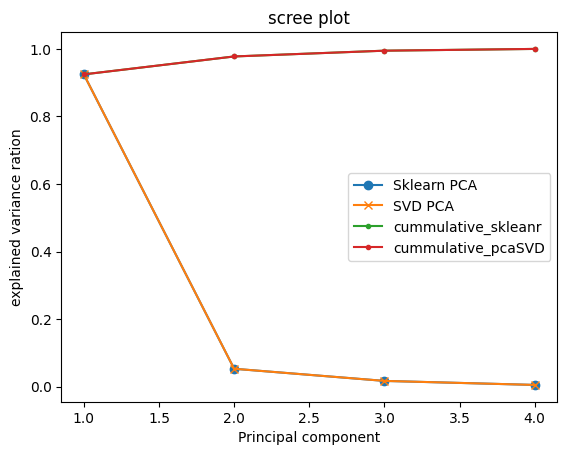

In [53]:
sk_ref_full=PCA(svd_solver='full').fit(X)
svd_ref_full=PCASVD(n_components=X.shape[1]).fit(X)
n = X.shape[1]
x = range(1, n+1)
plt.plot(x,sk_ref_full.explained_variance_ratio_,marker='o',label='Sklearn PCA')
plt.plot(x,svd_ref_full.explained_variance_ratio_,marker='x',label='SVD PCA')
plt.plot(x,np.cumsum(sk_ref_full.explained_variance_ratio_), marker='.',label='cummulative_skleanr')
plt.plot(x,np.cumsum(svd_ref_full.explained_variance_ratio_), marker='.',label='cummulative_pcaSVD')
plt.xlabel('Principal component')
plt.ylabel('explained variance ration')
plt.title('scree plot')
plt.legend()

In [54]:
def reconstruction_error(model, X):
    X = np.asarray(X, float)
    X_hat = model.inverse_transform(model.transform(X))
    err = X - X_hat
    return {
        "mse_per_element": (err**2).mean(),            # averaged over n*p
        "mse_per_sample":  (err**2).sum(1).mean(),     # squared distance per point
        "frobenius":       np.linalg.norm(err),
        "relative":        (err**2).sum() / ((X - X.mean(0))**2).sum(),
    }

ours = PCASVD(n_components=40).fit(X)
print(reconstruction_error(ours, X))


{'mse_per_element': np.float64(5.3853751872263265e-31), 'mse_per_sample': np.float64(2.1541500748905306e-30), 'frobenius': np.float64(1.7975608786174103e-14), 'relative': np.float64(4.74224322613244e-31)}


In [22]:
X_d,_=load_digits(return_X_y=True)

In [44]:
ours=PCASVD(n_components=40).fit(X_d)
ref=PCA(n_components=40,svd_solver='full').fit(X_d)
assert np.allclose(ours.explained_variance_ratio_,ref.explained_variance_ratio_)

In [45]:
M=np.abs(ours.components_ @ ref.components_.T)
assert np.allclose(np.diag(M),1.0,atol=1e-8)
print("scratch PCA == SKlearn PCA")

scratch PCA == SKlearn PCA


In [49]:
sk_ref_full_d=PCA(svd_solver='full').fit(X_d)
svd_ref_full_d=PCASVD(n_components=X_d.shape[1]).fit(X_d)
len(sk_ref_full_d.explained_variance_ratio_)

64

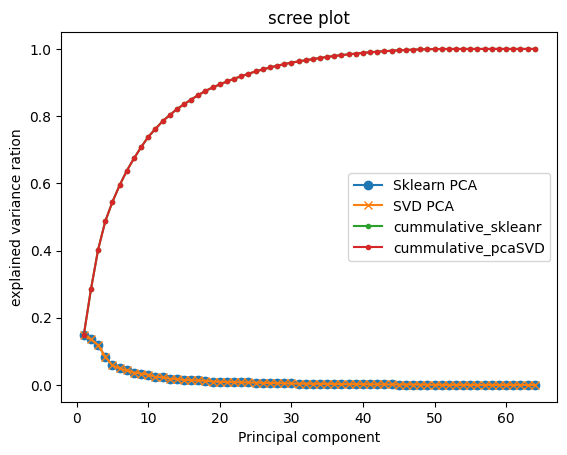

In [52]:
sk_ref_full_d=PCA(svd_solver='full').fit(X_d)
svd_ref_full_d=PCASVD(n_components=X_d.shape[1]).fit(X_d)
n = X_d.shape[1]
x = range(1, n+1)
plt.plot(x,sk_ref_full_d.explained_variance_ratio_,marker='o',label='Sklearn PCA')
plt.plot(x,svd_ref_full_d.explained_variance_ratio_,marker='x',label='SVD PCA')
plt.plot(x,np.cumsum(sk_ref_full_d.explained_variance_ratio_), marker='.',label='cummulative_skleanr')
plt.plot(x,np.cumsum(svd_ref_full_d.explained_variance_ratio_), marker='.',label='cummulative_pcaSVD')
plt.xlabel('Principal component')
plt.ylabel('explained variance ration')
plt.title('scree plot')
plt.legend()